# 01. Probability Distribution

Setelah notebook ini, mahasiswa diharapkan mampu:
1. menghitung mean, variance, dan standard deviation, serta membedakan parameter populasi dan statistik sampel;
2. memilih distribusi diskrit/kontinu yang cocok untuk suatu kasus dan membaca PMF, PDF, dan CDF;
3. menghitung probabilitas bersyarat dan menerapkan aturan Bayes pada kasus dua variabel.

## Setup

Jalankan sel ini lebih dahulu. Notebook ini memakai `scipy.stats` untuk semua distribusi.

In [2]:
# Standard setup cell - run before other cells.
import importlib.util
import subprocess
import sys

def ensure_dependencies():
    """Install only packages used by this module."""
    required = {"numpy": "numpy", "matplotlib": "matplotlib", "pandas": "pandas", "scipy": "scipy"}
    missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

ensure_dependencies()
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

rng = np.random.default_rng(42)

---
## 1.1 Variabel acak dan notasi

| Notasi | Arti | Contoh (lempar dadu) |
|---|---|---|
| $Y$ (huruf besar) | **variabel acak**: besaran yang hasilnya belum diketahui | hasil lemparan |
| $y$ (huruf kecil) | satu **nilai spesifik** yang mungkin muncul | $y=3$ |
| $P(Y=y)$ atau $p(y)$ | peluang $Y$ bernilai $y$ | $P(Y=3)=1/6$ |
| $\Omega$ | ruang sampel, semua hasil yang mungkin | $\{1,\dots,6\}$ |

Syarat setiap distribusi: $0\le p(y)\le 1$ dan $\sum_y p(y)=1$ (diskrit) atau $\int f(y)\,dy=1$ (kontinu).

---
## 1.2 Parameter data: mean, variance, standard deviation

| Ukuran | Populasi (parameter) | Sampel (statistik) |
|---|---|---|
| Rata-rata | $\mu = E[Y] = \sum_y y\,p(y)$ | $\bar{x} = \frac{1}{n}\sum_i x_i$ |
| Varians | $\sigma^2 = E[(Y-\mu)^2] = E[Y^2]-\mu^2$ | $s^2 = \frac{1}{n-1}\sum_i (x_i-\bar{x})^2$ |
| Simpangan baku | $\sigma=\sqrt{\sigma^2}$ | $s=\sqrt{s^2}$ |

- **Mean** = pusat data; **variance** = rata-rata kuadrat jarak ke pusat (satuannya kuadrat); **std dev** = sebaran dalam satuan asli.
- Populasi = seluruh objek (biasanya tidak bisa diukur semua). Sampel = sebagian yang diamati, dipakai untuk **menaksir** $\mu$ dan $\sigma^2$.
- Pembagi $n-1$ (*Bessel's correction*) dipakai karena $\bar{x}$ dihitung dari sampel yang sama, sehingga sebaran cenderung terlalu kecil bila dibagi $n$. Di NumPy: `np.var(x, ddof=1)`.

![populasi vs sampel](img/population-vs-sample.png)

### Contoh penerapan

In [3]:
# Populasi: dadu adil, dihitung langsung dari distribusinya
y = np.arange(1, 7)
p = np.full(6, 1 / 6)
mu = np.sum(y * p)
var = np.sum(y**2 * p) - mu**2          # E[Y^2] - mu^2
print(f"Populasi : mu = {mu:.4f}, sigma^2 = {var:.4f}, sigma = {np.sqrt(var):.4f}")

# Sampel: 20 lemparan
x = rng.integers(1, 7, size=20)
print(f"Sampel   : x = {x}")
print(f"           x_bar = {x.mean():.4f}, s^2 = {x.var(ddof=1):.4f}, s = {x.std(ddof=1):.4f}")

Populasi : mu = 3.5000, sigma^2 = 2.9167, sigma = 1.7078
Sampel   : x = [1 5 4 3 3 6 1 5 2 1 4 6 5 5 5 5 4 1 6 3]
           x_bar = 3.7500, s^2 = 3.1447, s = 1.7733


$\mu=3{,}5$ dan $\sigma^2=91/6-3{,}5^2\approx 2{,}9167$ adalah nilai pasti dari distribusi. $\bar{x}$ dan $s^2$ berubah tiap kali sampel diambil ulang dan makin dekat ke $\mu,\sigma^2$ ketika $n$ membesar.

---
## 1.3 Distribusi diskrit

Hasilnya **dapat dihitung** (*countable*). Peluang tiap nilai diberikan oleh **PMF** (*probability mass function*) $p(y)=P(Y=y)$.

| Distribusi | PMF $p(y)$ | $E[Y]$ | $\mathrm{Var}(Y)$ | Kapan dipakai / contoh |
|---|---|---|---|---|
| **Uniform** $U(a,b)$ | $\frac{1}{b-a+1}$, $y\in\{a,\dots,b\}$ | $\frac{a+b}{2}$ | $\frac{(b-a+1)^2-1}{12}$ | semua hasil sama peluang (*equiprobable*): dadu |
| **Bernoulli** $Bern(p)$ | $p^y(1-p)^{1-y}$, $y\in\{0,1\}$ | $p$ | $p(1-p)$ | **1 kali** percobaan sukses/gagal: klik iklan atau tidak |
| **Binomial** $B(n,p)$ | $\binom{n}{y}p^y(1-p)^{n-y}$ | $np$ | $np(1-p)$ | jumlah sukses dari $n$ Bernoulli **independen**: hari harga saham naik dalam 5 hari bursa |
| **Poisson** $Po(\lambda)$ | $\frac{\lambda^y e^{-\lambda}}{y!}$ | $\lambda$ | $\lambda$ | banyak kejadian per interval waktu/ruang: pertanyaan masuk ke chatbot per jam |

![distribusi diskrit](img/discrete-distributions.png)

Bernoulli adalah Binomial dengan $n=1$. Poisson mendekati Binomial bila $n$ besar dan $p$ kecil, dengan $\lambda=np$.

### Contoh penerapan

In [4]:
# Harga saham naik pada satu hari dengan p = 0,6. Berapa peluang naik tepat 3 dari 5 hari?
n, p_up = 5, 0.6
B = stats.binom(n, p_up)
print(f"P(Y=3)  = {B.pmf(3):.4f}")
print(f"P(Y>=4) = {B.sf(3):.4f}")   # sf(k) = P(Y > k)

# Chatbot menerima rata-rata 4 pertanyaan per jam. Peluang lonjakan >= 8 pertanyaan?
Po = stats.poisson(4)
print(f"P(Y>=8) = {Po.sf(7):.4f}")

# Cek rumus E dan Var dengan simulasi 100.000 sampel
dists = {"Uniform U(1,6)": stats.randint(1, 7), "Bern(0.7)": stats.bernoulli(0.7),
         "B(5, 0.6)": B, "Po(4)": Po}
display(pd.DataFrame([
    {"distribusi": name, "E teori": d.mean(), "Var teori": d.var(),
     "mean sim": (s := d.rvs(100_000, random_state=rng)).mean(), "var sim": s.var(ddof=1)}
    for name, d in dists.items()
]).round(4))

P(Y=3)  = 0.3456
P(Y>=4) = 0.3370
P(Y>=8) = 0.0511


,distribusi,E teori,Var teori,mean sim,var sim
0,"Uniform U(1,6)",3.5,2.9167,3.4997,2.9173
1,Bern(0.7),0.7,0.2100,0.7007,0.2097
2,"B(5, 0.6)",3.0,1.2000,2.9968,1.2084
3,Po(4),4.0,4.0000,3.9970,3.9617


Kolom simulasi hampir sama dengan kolom teori. Perhatikan `stats.randint(1, 7)`: batas atas SciPy bersifat eksklusif, jadi ini dadu $\{1,\dots,6\}$.

---
## 1.4 Distribusi kontinu

Nilai $Y$ berada pada rentang kontinu, sehingga ada tak hingga kemungkinan dan **$P(Y=y)=0$ untuk satu titik**. Yang bermakna adalah peluang pada **interval**:

$$P(a\le Y\le b)=\int_a^b f(y)\,dy = F(b)-F(a),\qquad F(y)=P(Y\le y)$$

$f(y)$ adalah **PDF** (*probability density function*, tinggi kurva, boleh > 1), $F(y)$ adalah **CDF** (*cumulative distribution function*, selalu naik dari 0 ke 1).

![pdf vs cdf](img/pdf-vs-cdf.png)

| Distribusi | Parameter | $E[Y]$ | $\mathrm{Var}(Y)$ | Ciri / contoh |
|---|---|---|---|---|
| **Normal** $N(\mu,\sigma^2)$ | $\mu,\sigma^2$ | $\mu$ | $\sigma^2$ | lonceng simetris; tinggi badan, derau sensor |
| **Standard Normal** $Z$ | - | $0$ | $1$ | hasil standardisasi $Z=\frac{Y-\mu}{\sigma}$ |
| **Student's t** $t(df)$ | $df=n-1$ | $0$ ($df>1$) | $\frac{df}{df-2}$ ($df>2$) | sampel kecil ($n<30$); ekor tebal mengantisipasi *outlier*; $\to Z$ bila $df\to\infty$ |
| **Chi-squared** $\chi^2(k)$ | $k$ | $k$ | $2k$ | non-negatif, miring ke kanan; uji *goodness of fit* |
| **Exponential** $Exp(\lambda)$ | $\lambda$ (laju) | $1/\lambda$ | $1/\lambda^2$ | turun cepat lalu melandai; *views* video setelah upload, waktu tunggu antar-kejadian Poisson |
| **Logistic** $Logistic(\mu,s)$ | $\mu,s$ | $\mu$ | $\frac{s^2\pi^2}{3}$ | CDF-nya kurva S $\frac{1}{1+e^{-(y-\mu)/s}}$; input kontinu ->peluang biner (menang/kalah e-sports) |

![distribusi kontinu](img/continuous-distributions.png)

### Normal, aturan empiris, dan Z-score

Untuk data normal, sekitar **68%** data berada dalam $\mu\pm\sigma$, **95%** dalam $\mu\pm2\sigma$, dan **99,7%** dalam $\mu\pm3\sigma$. Z-score mengubah nilai apa pun menjadi "berapa $\sigma$ dari mean", sehingga data berbeda satuan bisa dibandingkan.

![aturan empiris](img/empirical-rule.png)

### Contoh penerapan

In [5]:
# Aturan empiris dari CDF normal baku
for k in (1, 2, 3):
    print(f"P(|Z| <= {k}) = {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}")

# Tinggi mahasiswa ~ N(170, 8^2). Peluang tinggi antara 160 dan 180 cm?
mu_h, sigma_h = 170, 8
z_lo, z_hi = (160 - mu_h) / sigma_h, (180 - mu_h) / sigma_h
print(f"\nZ = [{z_lo}, {z_hi}] -> P = {stats.norm.cdf(z_hi) - stats.norm.cdf(z_lo):.4f}")
print(f"Langsung N(170, 8): P = {stats.norm(mu_h, sigma_h).cdf(180) - stats.norm(mu_h, sigma_h).cdf(160):.4f}")
print(f"P(Y = 170) = 0, tetapi f(170) = {stats.norm(mu_h, sigma_h).pdf(170):.4f} (kepadatan, bukan peluang)")

# Ekor tebal: peluang |nilai| > 3 pada Normal vs t
for name, d in [("N(0,1)", stats.norm), ("t(df=4)", stats.t(4))]:
    print(f"P(|Y| > 3) {name:8s}= {2 * d.sf(3):.4f}")

P(|Z| <= 1) = 0.6827
P(|Z| <= 2) = 0.9545
P(|Z| <= 3) = 0.9973

Z = [-1.25, 1.25] -> P = 0.7887
Langsung N(170, 8): P = 0.7887
P(Y = 170) = 0, tetapi f(170) = 0.0499 (kepadatan, bukan peluang)
P(|Y| > 3) N(0,1)  = 0.0027
P(|Y| > 3) t(df=4) = 0.0399


Z-score $[-1{,}25;\ 1{,}25]$ memberi peluang yang sama dengan menghitung langsung pada $N(170,8^2)$. Distribusi $t(4)$ memberi peluang nilai ekstrem sekitar 15 kali lebih besar daripada normal, itulah arti "ekor tebal".

---
## 1.5 Joint, conditional, dan aturan Bayes

Contoh klasik (Russell & Norvig): dua variabel Boolean, *Cavity* (gigi berlubang) dan *Toothache* (sakit gigi). Tabel **joint distribution** berisi peluang setiap kombinasi, jumlahnya 1:

| | toothache | ¬toothache | **marginal** |
|---|---|---|---|
| **cavity** | 0,12 | 0,08 | $P(cavity)=0{,}20$ |
| **¬cavity** | 0,08 | 0,72 | 0,80 |
| **marginal** | $P(toothache)=0{,}20$ | 0,80 | 1 |

Dari tabel itu:

| Konsep | Rumus | Contoh |
|---|---|---|
| Joint | $P(A\cap B)$ | $P(cavity \wedge toothache)=0{,}12$ |
| Marginal | $P(A)=\sum_b P(A, b)$ | $P(cavity)=0{,}12+0{,}08=0{,}20$ |
| Conditional | $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ | $P(cavity\mid toothache)=0{,}12/0{,}20=0{,}6$ |
| Product rule | $P(A\cap B)=P(A\mid B)P(B)=P(B\mid A)P(A)$ | |
| Independen | $P(A\mid B)=P(A)$ | tidak berlaku di sini: $0{,}6\ne0{,}2$ |

### Aturan Bayes

Dari product rule diperoleh:

$$\underbrace{P(H\mid E)}_{\text{posterior}}=\frac{\overbrace{P(E\mid H)}^{\text{likelihood}}\;\overbrace{P(H)}^{\text{prior}}}{\underbrace{P(E)}_{\text{evidence}}},\qquad P(E)=P(E\mid H)P(H)+P(E\mid\neg H)P(\neg H)$$



### Contoh penerapan

In [10]:
joint = pd.DataFrame([[0.12, 0.08], [0.08, 0.72]],
                     index=["cavity", "no_cavity"], columns=["toothache", "no_toothache"])
p_toothache = joint["toothache"].sum()
p_cavity = joint.loc["cavity"].sum()
print(f"P(toothache)          = {p_toothache:.2f}")
print(f"P(cavity | toothache) = {joint.loc['cavity', 'toothache'] / p_toothache:.2f}")

def bayes(prior, likelihood, false_pos):
    """Posterior P(H|E) untuk satu hipotesis biner."""
    evidence = likelihood * prior + false_pos * (1 - prior)
    return likelihood * prior / evidence

# Cara Bayes untuk cavity: P(toothache|cavity) dan P(toothache|no_cavity) dari tabel
lik = joint.loc["cavity", "toothache"] / p_cavity
fp = joint.loc["no_cavity", "toothache"] / (1 - p_cavity)
print(f"Bayes                 = {bayes(p_cavity, lik, fp):.2f}")

# Tes medis
post = bayes(prior=0.01, likelihood=0.90, false_pos=0.09)
print(f"\nP(sakit | +) = {post:.4f}")

# Tes kedua (independen bersyarat status penyakit): posterior lama menjadi prior baru
post2 = bayes(prior=post, likelihood=0.90, false_pos=0.09)
print(f"P(sakit | +, +) = {post2:.4f}")

P(toothache)          = 0.20
P(cavity | toothache) = 0.60
Bayes                 = 0.60

P(sakit | +) = 0.0917
P(sakit | +, +) = 0.5025


---
## 1.6 Inference dari tabel joint

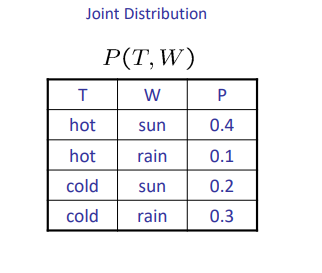

Contoh slide CS188

| Konsep | Inti | Hasil |
|---|---|---|
| **Event** | himpunan outcome, $P(E)=\sum_{x\in E}P(x)$ | $P(hot \lor sun)=0{,}4+0{,}1+0{,}2=0{,}7$ |
| **Conditional distribution** | satu tabel penuh untuk tiap nilai bukti, jumlahnya 1 | $P(W\mid hot)$: sun 0,8 · rain 0,2 |
| **Normalisasi** | bagi setiap entri dengan $Z=$ jumlah semua entri | $[0{,}1;\ 0{,}3]\xrightarrow{Z=0{,}4}[0{,}25;\ 0{,}75]$ |
| **Chain rule** | $P(x_1,\dots,x_n)=\prod_i P(x_i\mid x_1,\dots,x_{i-1})$ | $P(s,t,w)=P(s)\,P(t\mid s)\,P(w\mid s,t)$ |

**Inference by enumeration**: menghitung $P(Q\mid e)$ dari tabel joint dalam 3 langkah.

1. **Select**: ambil baris yang cocok dengan bukti $e$.
2. **Sum out**: jumlahkan variabel tersembunyi $H$ sehingga tersisa $P(Q,e)$.
3. **Normalize**: bagi dengan $Z=\sum_q P(q,e)=P(e)$.

Kelemahannya, tabel joint berukuran $d^n$ ($n$ variabel, $d$ nilai per variabel), sehingga waktu dan memorinya $O(d^n)$. **Independensi** memangkas ukuran itu: jika $P(x,y)=P(x)P(y)$ untuk **semua** sel, $n$ koin cukup disimpan sebagai $n$ tabel kecil, bukan $2^n$ baris. Pada **conditional independence**, variabel saling lepas setelah penyebabnya diketahui, misalnya *Traffic* ⫫ *Umbrella* | *Rain* dan *Alarm* ⫫ *Fire* | *Smoke*.

### Contoh penerapan

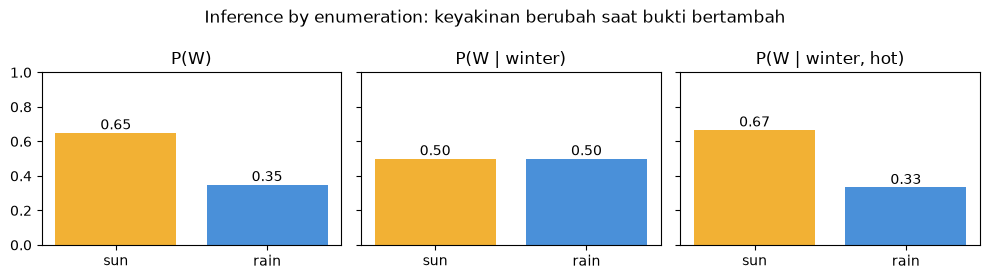

Chain rule menghasilkan joint yang sama: True


In [7]:
joint3 = pd.DataFrame({
    "S": ["summer"] * 4 + ["winter"] * 4,
    "T": ["hot", "hot", "cold", "cold"] * 2,
    "W": ["sun", "rain"] * 4,
    "P": [0.30, 0.05, 0.10, 0.05, 0.10, 0.05, 0.15, 0.20],
})

def enumerate_query(joint, query, evidence=None):
    """P(query | evidence) dengan select -> sum out -> normalize."""
    sel = joint
    for var, val in (evidence or {}).items():
        sel = sel[sel[var] == val]               # 1. select
    summed = sel.groupby(query)["P"].sum()       # 2. sum out variabel lain
    return summed / summed.sum()                 # 3. normalize, Z = P(evidence)

queries = {"P(W)": {}, "P(W | winter)": {"S": "winter"}, "P(W | winter, hot)": {"S": "winter", "T": "hot"}}
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, (title, ev) in zip(axes, queries.items()):
    res = enumerate_query(joint3, "W", ev)[["sun", "rain"]]
    ax.bar(res.index, res.values, color=["#f2b134", "#4a90d9"])
    for i, v in enumerate(res.values):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
    ax.set_title(title)
axes[0].set_ylim(0, 1)
fig.suptitle("Inference by enumeration: keyakinan berubah saat bukti bertambah")
plt.tight_layout()
plt.show()

# Chain rule: susun ulang joint dari P(S) * P(T|S) * P(W|S,T)
f = joint3.copy()
p_s = f.groupby("S")["P"].transform("sum")
p_st = f.groupby(["S", "T"])["P"].transform("sum")
f["P(S)P(T|S)P(W|S,T)"] = p_s * (p_st / p_s) * (f["P"] / p_st)
print("Chain rule menghasilkan joint yang sama:", np.allclose(f["P"], f["P(S)P(T|S)P(W|S,T)"]))

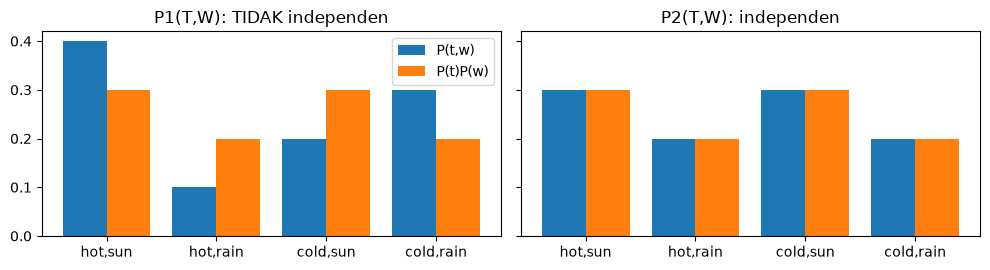

In [8]:
# Independensi: bandingkan P(t,w) dengan P(t)P(w) di setiap sel
tables = {"P1(T,W)": [0.4, 0.1, 0.2, 0.3], "P2(T,W)": [0.3, 0.2, 0.3, 0.2]}
labels = ["hot,sun", "hot,rain", "cold,sun", "cold,rain"]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (name, p) in zip(axes, tables.items()):
    J = np.array(p).reshape(2, 2)                     # baris T, kolom W
    prod = np.outer(J.sum(axis=1), J.sum(axis=0))     # P(t) * P(w)
    x = np.arange(4)
    ax.bar(x - 0.2, J.ravel(), 0.4, label="P(t,w)")
    ax.bar(x + 0.2, prod.ravel(), 0.4, label="P(t)P(w)")
    ax.set_xticks(x, labels)
    ax.set_title(f"{name}: {'independen' if np.allclose(J, prod) else 'TIDAK independen'}")
axes[0].legend()
plt.tight_layout()
plt.show()

Bukti *winter* membuat peluang hujan naik dari 0,35 ke 0,50, lalu bukti *hot* menurunkannya ke 0,33. Hitungan ini memakai tiga langkah yang sama dengan normalization trick. Chain rule menyusun ulang joint yang sama persis dari potongan-potongan conditional. Pada $P_1$ batang joint dan batang perkalian marginal berbeda, jadi $T$ dan $W$ saling bergantung. Pada $P_2$ keduanya sama di semua sel, jadi tabel itu cukup disimpan sebagai $P(T)$ dan $P(W)$.

---
## Latihan (dikerjakan di kertas)
Tuliskan rumus yang dipakai, substitusi angka, dan hasil akhir (rounding 2 angka di belakang koma). 

Gunakan tabel bantu berikut.

| Nilai | Hasil |
|---|---|
| $e^{-1}$ | 0,37 |
| $0{,}8^4$ | 0,41 |
| $0{,}8^5$ | 0,33 |
| $\Phi(1)=P(Z\le 1)$ | 0,84 |
| $\Phi(1{,}28)$ | 0,90 |
| $\Phi(1{,}5)$ | 0,93 |
| $\Phi(2)$ | 0,98 |
| $\sqrt{42}$ | 6,48 |

Note: $\Phi(-z)=1-\Phi(z)$.

### Soal 1 - Parameter data

Waktu respons server (ms) dari 8 permintaan: `123, 131, 116, 172, 127, 132, 116, 123`.

1. Hitung $\bar{x}$, $s^2$, dan $s$. Gunakan tabel kerja dengan kolom $x_i$, $x_i-\bar{x}$, dan $(x_i-\bar{x})^2$.
2. Hitung juga varians dengan pembagi $n$. Mana yang tepat dipakai di sini dan mengapa?
3. Hitung Z-score setiap data (pakai $\bar{x}$ dan $s$). Data mana yang mencurigakan bila batasnya $|Z|>2$?
4. Buang data tersebut, lalu hitung ulang $\bar{x}$ dan $s^2$. Ukuran mana yang berubah paling besar?

<details>
<summary>Klik untuk melihat hint</summary>

Data ini adalah sampel, bukan seluruh populasi permintaan. Jumlah $(x_i-\bar{x})^2$ seharusnya bulat dan habis dibagi $n-1$. Untuk bagian 4, hitung selisih tiap data terhadap mean baru, bukan mean lama.

</details>

### Soal 2 - Memilih distribusi

Untuk setiap kasus, tentukan distribusi dan parameternya, tuliskan rumus PMF/PDF/CDF yang dipakai, lalu hitung peluang yang diminta.

1. Model klasifikasi gambar benar dengan peluang 0,8 per gambar. Dari 5 gambar, berapa peluang **paling sedikit** 4 benar? Berapa $E[Y]$ dan $\mathrm{Var}(Y)$?
2. Server menerima rata-rata 1 *error log* per menit. Berapa peluang dalam satu menit **tidak ada** error? Berapa peluang **lebih dari 1** error?
3. Nilai ujian ~ $N(70, 10^2)$. Berapa persen mahasiswa mendapat nilai di atas 90? Berapa persen yang nilainya antara 60 dan 85? Nilai minimal berapa agar masuk 10% teratas?
4. Waktu sampai error berikutnya pada kasus 2 mengikuti $Exp(\lambda)$. Berapa rata-rata waktu tunggunya? Berapa peluang menunggu lebih dari 1 menit? Bandingkan dengan jawaban "tidak ada error" pada nomor 2 dan jelaskan.

<details>
<summary>Klik untuk melihat hint</summary>

Bedakan "jumlah sukses dari $n$ percobaan" dengan "jumlah kejadian per interval". "Lebih dari 1" lebih mudah dihitung sebagai $1-P(Y\le 1)$. Untuk normal, ubah ke Z-score lalu baca tabel bantu; untuk 10% teratas cari $z$ dengan $\Phi(z)=0{,}90$ lalu $y=\mu+z\sigma$. Pada eksponensial, $P(T>t)=e^{-\lambda t}$.

</details>

### Soal 3 - Bayes dan confidence threshold

Sebuah filter spam mendeteksi kata "gratis". Diketahui 20% email adalah spam, $P(\text{gratis}\mid spam)=0{,}8$, dan $P(\text{gratis}\mid \neg spam)=0{,}1$.

1. Susun tabel joint $2\times2$ untuk *Spam* dan *Gratis* lengkap dengan marginalnya, lalu tentukan $P(\text{gratis})$.
2. Hitung $P(spam\mid \text{gratis})$ dan $P(spam\mid \neg\text{gratis})$.
3. Filter memindahkan email ke folder spam hanya jika posterior > 0,8. Apakah email berisi "gratis" dipindahkan? Berapa nilai $P(\text{gratis}\mid\neg spam)$ maksimum agar email itu dipindahkan?
4. Jelaskan mengapa menaikkan threshold mengurangi *false positive* tetapi menambah spam yang lolos.

<details>
<summary>Klik untuk melihat hint</summary>

Isi tabel joint dengan product rule $P(A\cap B)=P(B\mid A)P(A)$; keempat sel harus berjumlah 1. Untuk bagian 3, tulis posterior sebagai fungsi dari $x=P(\text{gratis}\mid\neg spam)$, yaitu $\frac{0{,}16}{0{,}16+0{,}8x}$, set sama dengan 0,8, lalu selesaikan.

</details>